In [1]:
import sys
import os
import pandas as pd
sys.path.append(os.path.abspath(".."))
from churn.modelo import dividir_datos, construir_modelo
from churn.datos import cargar_datos
from churn.eda import graficar_tasa
from churn.metricas import precision_at_k, lift_at_k, tabla_ganancias
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression
from churn import config

In [2]:
df = cargar_datos("../data/dataset.csv")

In [3]:
X_train, X_test, y_train, y_test = dividir_datos(df)

In [4]:
def resumir_cv(tit_nombre: str, nombre: str, resultado: dict) -> dict:
    return {
        tit_nombre: nombre,
        "auc_train": resultado["train_score"].mean(),
        "auc_val": resultado["test_score"].mean(),
        "auc_val_std": resultado["test_score"].std(),
    }

filas = []
# pd.DataFrame(filas)

In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=config.SEMILLA)

In [6]:
resultado_sin_limite = cross_validate(
    construir_modelo(config.NUM_COLS, config.CAT_COLS, DecisionTreeClassifier()),
    X_train, y_train,
    cv=cv,
    scoring="roc_auc",
    return_train_score=True,
    error_score="raise"
)

In [7]:
filas.append(resumir_cv("max_depth","None", resultado_sin_limite))

In [8]:
resultado_max_5 = cross_validate(
    construir_modelo(config.NUM_COLS, config.CAT_COLS, DecisionTreeClassifier(max_depth=5)),
    X_train, y_train,
    cv=cv,
    scoring="roc_auc",
    return_train_score=True,
    error_score="raise"
)

In [9]:
filas.append(resumir_cv("max_depth","5", resultado_max_5))

En la siguiente tabla se muestra como al no poner un límite de profundidad para el árbol de decisión, el modelo hace overfitting: El desempeño en train es perfecto (1.0) mientras que en validación es mucho más bajo (0.55), incluso peor que cuando se usó la regla de eqpdays (0.57). El modelo memoriza el ruido de train

Por otro lado, cuando se le agrega una profundidad máxima de 5, aunque supera lo que se obtuvo con Regresión Logística (tran = val = 0.61), sigue estando con uderfittng: el desempeño de train es bajo y la validación es también baja, parecido a train. El modelo es demasiado simple para el patrón

In [10]:
pd.DataFrame(filas)

,max_depth,auc_train,auc_val,auc_val_std
0,None,1.000000,0.548791,0.003617
1,5,0.639956,0.634432,0.002417


In [11]:
resultado_rand_forest_clf = cross_validate(
    construir_modelo(
        config.NUM_COLS,config.CAT_COLS,
        RandomForestClassifier(
            n_estimators=200,
            min_samples_leaf=50,
            n_jobs=-1,
            random_state=config.SEMILLA
        )
    ),
    X_train, y_train,
    cv=cv,
    scoring="roc_auc",
    return_train_score=True,
    error_score="raise"
)

In [12]:
filas.clear()
filas.append(resumir_cv("modelo","RandomForestClassifier", resultado_rand_forest_clf))

In [13]:
resultado_lgbm_clf_imp = cross_validate(
    construir_modelo(
        config.NUM_COLS,config.CAT_COLS,
        LGBMClassifier(
            random_state=config.SEMILLA,
            verbose=-1
        )
    ),
    X_train, y_train,
    cv=cv,
    scoring="roc_auc",
    return_train_score=True,
    error_score="raise"
)

In [14]:
filas.append(resumir_cv("modelo","LGBMClassifier (imputando)", resultado_lgbm_clf_imp))

In [15]:
resultado_lgbm_clf = cross_validate(
    construir_modelo(
        config.NUM_COLS,config.CAT_COLS,
        LGBMClassifier(
            random_state=config.SEMILLA,
            verbose=-1
        ),
        False
    ),
    X_train, y_train,
    cv=cv,
    scoring="roc_auc",
    return_train_score=True,
    error_score="raise"
)

In [16]:
filas.append(resumir_cv("modelo","LGBMClassifier (sin impotar)", resultado_lgbm_clf))

En la tabla de abajo se puede observar que el modelo que mejor desempeño tuvo fue LGBMClassifier sin imputar ni escalar variables numéricas. No mostró ni sobreaujuste ni subajuste: su val salió ~5 puntos debajo de train, lo cual no es suficiente para decir que hay sobreajuste.

Aquí quise hacer dos comparaciones para el mismo modelo de LGBMClassifier, una imputando y escalando y otra sin hacerlo. Observé que se comportó practicamente igual, eligo la versión más simple (sin imputar).

LightLGB, es un algoritmo basado en histogramas, diseñado para manejar datos dispersos y valores nulos de forma nativa.
Durante la fase de entrenamiento, cuando encuentra valores nulos en una variable, no falla. En su lugar, prueba temporalmente dos escenarios:
1. Enviar los nulos a la rama **izquierda**.
1. Enviar los nulos a la rama **derecha**.

El algoritmo calcula cuál de las dos opciones reduce más el error del modelo. Cuando el modelo ya está entrenado y recibe datos faltantes, direcciona esos datos hacia el lado por defecto que aprendió.

In [17]:
pd.DataFrame(filas)

,modelo,auc_train,auc_val,auc_val_std
0,RandomForestClassifier,0.738740,0.666932,0.003991
1,LGBMClassifier (imputando),0.737532,0.679870,0.002688
2,LGBMClassifier (sin impotar),0.738928,0.680010,0.002185


### Pruebas de hiperparámetros

In [18]:
cfg_1 = LGBMClassifier(random_state=config.SEMILLA, subsample=0.8)

cfg_2 = LGBMClassifier(
    n_estimators=400,
    learning_rate=0.05,
    num_leaves=15,
    min_child_samples=100,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    random_state=config.SEMILLA
)

cfg_3 = LGBMClassifier(
    n_estimators=1000,
    learning_rate=0.1,
    num_leaves=63,
    random_state=config.SEMILLA,
    subsample=0.8
)

In [19]:
config_regularizada = LGBMClassifier(**config.HIPERPARAMETROS)

Usé árboles pequeños (15 hojas, profundidad 5) y una tasa de aprendizaje baja con 300 árboles, para que el modelo aprenda patrones generales y no memorice.

Exijo al menos 50 clientes por hoja, para que ninguna regla se base en un grupo demasiado chico.



In [20]:
config_profunda = LGBMClassifier(
    learning_rate= 0.01,   # Aprendizaje muy lento
    n_estimators= 1000,    # Compensa el aprendizaje lento con muchos árboles
    num_leaves= 63,        # Permite árboles muy complejos
    max_depth= 8,          # Ligeramente profundo
    subsample= 0.9,
    colsample_bytree= 0.9, # cada árbol ve solo el 80 % de las columnas, elegidas al azar
    random_state= config.SEMILLA
)

In [21]:
config_dart = LGBMClassifier(
    boosting_type= 'dart', # Cambio radical en la construcción del ensamble
    learning_rate= 0.1,
    n_estimators= 200,
    drop_rate= 0.1,        # Probabilidad de apagar un árbol
    skip_drop= 0.5,        # Probabilidad de saltarse el proceso de dropout en una iteración
    max_drop= 50,          # Máximo de árboles apagados a la vez
    random_state= config.SEMILLA
)

In [22]:
configuraciones = {
    'default':      cfg_1, 
    'cfg_2':        cfg_2, 
    'cfg_3':        cfg_3, 
    'regularizada': config_regularizada, 
    'profunda':     config_profunda, 
    'dart':         config_dart
}

In [23]:
def resumir_cv(nombre: str, resultado: dict) -> dict:
    train = resultado["train_score"].mean()
    validacion = resultado["test_score"].mean()
    brecha = abs(train - validacion)
    return {
        'configuración': nombre,
        "train": train,
        "val": validacion,
        "brecha": brecha,
    }
# pd.DataFrame(filas)

In [24]:
filas.clear()

for cfg, estimador in configuraciones.items():
    resultado = cross_validate(
        construir_modelo(config.NUM_COLS, config.CAT_COLS,estimador,False),
        X_train, y_train,
        cv=cv,
        scoring="roc_auc",
        return_train_score=True,
        error_score="raise"
    )
    filas.append(resumir_cv(cfg, resultado))

In [25]:
pd.DataFrame(filas)

,configuración,train,val,brecha
0,default,0.738928,0.680010,0.058918
1,cfg_2,0.728613,0.682820,0.045794
2,cfg_3,0.987739,0.661611,0.326128
3,regularizada,0.715042,0.680393,0.034650
4,profunda,0.778020,0.682799,0.095221
5,dart,0.714886,0.678919,0.035967


Se puede observar que de estas configuraciones la que más sobrejusta es cfg_3. Se nota porque el train es muy alto (0.99) y el val muy bajo (0.66).

Entre estos 6 modelos, el mejor es el de configuración regularizada. Esta configuración está pensada para restringir la complejidad del árbol y fuerza al modelo a aprender patrones más generales. Se puede ver que los valores de train y val no distan mucho uno del otro, apenas 0.035 siendo la brecha más corta, demostrando así tener un menor grado de sobreajuste y superando a la regresión logística en val (61%) por ~7 puntos. A pesar de que Regresión Logística es más interpretable, la diferencia de desempeño es lo suficientemente considerable para decidir cambiar de algoritmo por uno que ofreciera un mejor desempeño más aún en términos de precisión.

La brecha entre train y validación es de 0.035 de AUC, contra 0.33 de una configuración sin restricciones: esa es la evidencia de que el sobreajuste está controlado.

### Evaluación final sobre el test

In [26]:
puntuacion_regla = X_test["eqpdays"].fillna(X_train["eqpdays"].median())

In [27]:
resultado_regresion =construir_modelo(
    config.NUM_COLS, config.CAT_COLS,
    LogisticRegression(C=1.0, max_iter=2000)
).fit(X_train, y_train).predict_proba(X_test)

In [28]:
resultado_LightGBM = (
    construir_modelo(config.NUM_COLS, config.CAT_COLS,config_regularizada,False)
    .fit(X_train, y_train)
    .predict_proba(X_test)
)

In [29]:
def armar_fila(nombre: str, y_true: list[int], scores: list[float]) -> dict:
    k_10 = int(0.10 * len(y_true))
    k_20 = int(0.20 * len(y_true))
    return {
        "Modelo": nombre,
        "AUC": f"{roc_auc_score(y_true, scores):.3f}",
        "precision@10%": f"{precision_at_k(y_true, scores,k_10):.0%}",
        "lift@10%": f"{lift_at_k(y_true, scores,k_10):.3}",
        "precision@20%": f"{precision_at_k(y_true, scores,k_20):.0%}",
    }
# pd.DataFrame(filas)

In [30]:
filas_test_final = [
    armar_fila("Regla 'eqpdays'", y_test, puntuacion_regla),
    armar_fila("Logística", y_test, resultado_regresion[:, 1]),
    armar_fila("LightGBM", y_test, resultado_LightGBM[:, 1]),
]

pd.DataFrame(filas_test_final)

,Modelo,AUC,precision@10%,lift@10%,precision@20%
0,Regla 'eqpdays',0.571,58%,1.18,56%
1,Logística,0.607,64%,1.3,62%
2,LightGBM,0.680,78%,1.58,72%


In [31]:
ganancias_lgbm = tabla_ganancias(y_test, resultado_LightGBM[:, 1])
ganancias_lgbm

,n_clientes,churners,tasa_churn,score_promedio,lift,captura_acumulada
grupo,,,,,,
1,2000,1566,0.7830,0.740137,1.579903,0.157990
2,2000,1316,0.6580,0.644582,1.327684,0.290759
3,2000,1162,0.5810,0.596914,1.172316,0.407990
4,2000,1122,0.5610,0.559732,1.131961,0.521186
5,2000,1009,0.5045,0.527002,1.017958,0.622982
6,2000,996,0.4980,0.491669,1.004843,0.723467
7,2000,897,0.4485,0.451935,0.904964,0.813963
8,2000,819,0.4095,0.404450,0.826271,0.896590
9,2000,617,0.3085,0.330503,0.622478,0.958838


El score promedio se parece a tasa_churn en cada grupo. El modelo predice 74 % en el primer grupo y la tasa real es 78 %; predice 23 % en el último y la real es 20 %. Está bien calibrado, con una ligera tendencia a quedarse corto en los extremos.

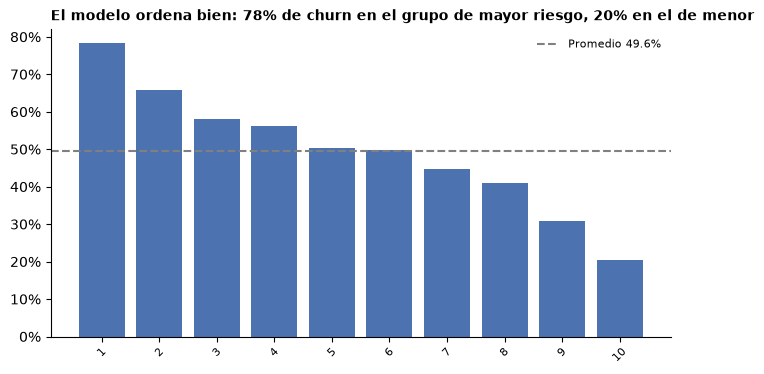

In [32]:
promedio = y_test.mean()
fig = graficar_tasa(ganancias_lgbm,"El modelo ordena bien: 78% de churn en el grupo de mayor riesgo, 20% en el de menor", promedio)

**Traducción de negocio:** Si contactamos al 10% de clientes con mayor riesgo, 78 de cada 100 realmente se iban, contra 50 si contactaramos al azar.

**Supuestos:** contactar a un cliente cuesta $10, una oferta retiene al 20% de de los que se iban, y un cliente retenido vale 6 meses de su rev_Mean.

In [33]:
df_test_clasificado = pd.DataFrame(X_test['rev_Mean'].copy().fillna(0))
df_test_clasificado['churn'] = y_test
df_test_clasificado['resultado_LightGBM'] = resultado_LightGBM[:,1]
df_test_clasificado = df_test_clasificado.sort_values(by='resultado_LightGBM', ascending=False)

In [34]:
pd.options.display.float_format = '{:,.2f}'.format

In [35]:
costo_contacto = 10
tasa_retencion = 0.20
meses_LTV = 6
filas_supuesto = []
n = len(df_test_clasificado)

for pct in range(10,110,10):
    k = int(n * (pct/100))
    df_pct = df_test_clasificado.copy().head(k)
    precision = precision_at_k(
        df_pct['churn'],
        df_pct['resultado_LightGBM'],
        k
    )
    rev_Mean = df_pct[df_pct['churn'] == 1]['rev_Mean'].mean()
    churners = df_pct['churn'].sum()
    costo_campana = float(costo_contacto * k)
    clientes_rescatados = churners * tasa_retencion
    ingreso_recuperado = clientes_rescatados*6*rev_Mean
    ganancia_marginal = ingreso_recuperado-costo_campana
    filas_supuesto.append({
        "Top": f"{pct}%",
        "n_clientes": k,
        "churners": churners,
        "precision": f"{precision:.0%}",
        "Costo ($)": -costo_campana,
        "Rescatados (20%)": clientes_rescatados,
        "Ingreso Recuperado ($)": ingreso_recuperado,
        "Ganancia ($)": ganancia_marginal
    })

df_resultados = pd.DataFrame(filas_supuesto)
df_resultados["Incremento ($)"] = df_resultados["Ganancia ($)"].diff()
df_resultados

,Top,n_clientes,churners,precision,Costo ($),Rescatados (20%),Ingreso Recuperado ($),Ganancia ($),Incremento ($)
0,10%,2000,1566,78%,"-20,000.00",313.20,"105,911.12","85,911.12",NaN
1,20%,4000,2882,72%,"-40,000.00",576.40,"196,311.38","156,311.38","70,400.26"
2,30%,6000,4044,67%,"-60,000.00",808.80,"271,941.20","211,941.20","55,629.81"
3,40%,8000,5166,65%,"-80,000.00","1,033.20","343,861.12","263,861.12","51,919.93"
4,50%,10000,6175,62%,"-100,000.00","1,235.00","408,102.81","308,102.81","44,241.69"
5,60%,12000,7171,60%,"-120,000.00","1,434.20","473,794.32","353,794.32","45,691.51"
6,70%,14000,8068,58%,"-140,000.00","1,613.60","535,115.74","395,115.74","41,321.42"
7,80%,16000,8887,56%,"-160,000.00","1,777.40","600,308.81","440,308.81","45,193.07"
8,90%,18000,9504,53%,"-180,000.00","1,900.80","655,606.28","475,606.28","35,297.47"
9,100%,20000,9912,50%,"-200,000.00","1,982.40","684,464.75","484,464.75","8,858.47"


En la tabla anterior se puede ver que mientras más clientes se contactan, mayor es la ganancia total. Esto sucede simplemente porque este análisis se hace sobre un dataset balanceado (tasa de churn promedio del 49.6%), algo que está fuera de la realidad. 

Con estos supuestos, contactar a cualquier grupo es rentable, pero el retorno cae de $70 mil a $9 mil por cada 10 % adicional. Si la capacidad del equipo es limitada, el orden del modelo indica por dónde empezar. Con la tasa real de churn de una telco, el punto de equilibrio llegaría mucho antes.